# Portfolio Optimization
A notebook combining the in-sample calculations and the out-of-sample calculations to easily run at once.  

## Part 1: MVO Portfolio Implementation

### Objective
Construct and compare optimal investment portfolios using 96 months of historical for 11 sector ETFs. Apply modern portfolio theory (Markowitz Optimization) to identify portfolios that minimize risk, maximize risk-adjusted returns, and improve upon a client's existing portfolio.  

### Portfolio Constraints  
1. Budget Constraint: $\sum_i w_i = 1$
2. Client Portfolio: Weights must be nonnegative and sum to 1.  
3. Global Minimum Variance: Minimize variance subject to the budget constraint.  
4. Efficient Portfolio: Minimize variance subject to the budget constraint and the expected returns must match the expected returns of the client portfolio $w^T \mu = R_{\text{target}}$  
5. Optimal Risky Portfolio: Maximize Sharpe ratio subject to the busget constraint  
6. Efficient Frontier: Linear combinations of GMV and EP; budget constaint  
7. Capital Allocation Line: Allocate $y$ to the ORP and $1-y$ to the risk-free asset  

### Implementation
1. Data Preparation: Load historical ETF returns and calculate annualized expected returns, covariance matrix and risk-free rate.  
2. Client Portfolio: Accept user-defined or randomly generated portfolio weights. Verify the budget constraint and calculate the expected return, variance, standard deviation, and Sharpe ratio.  
3. Global Minimum Variance Portfolio (GMV):  Determine the portfolio with the lowest possible variance using both the closed-form solution and a constrained matrix optimization approach.  
4. Efficient Portfolio (EP): Find the minimum-variance portfolio that achieves the client's expected return using a Lagrangian matrix system.  
5. Optimal Risky Portfolio (ORP): Calculate the tangency portfolio that maximizes the Sharpe ratio using the covariance matrix, expected returns, and risk-free rate.
6. Efficient Frontier: Generate portfolios as linear combinations of the GMV and efficient portfolio and then plot the Efficient Frontier.  
7. Capital Allocation Line (CAL): Combine the risk-free asset with the ORP to evaluate different levels of risk exposure, including leveraged portfolios.  
8. Fund Separation Theorem: Construct two portfolios along the CAL: one matching the client's expected return and another matching the client's risk. Quantify improvements in risk or return.  
9. Visualization: Plot the efficient frontier, inefficient branch, CAL, and key portfolios to compare their risk-return characteristics.  

### Expected Outcome
Show how portfolio optimization can improve efficiency by reducing risk for a given expected return or increasing expected return for a given level of risk, while illustrating the benefits of diversification and combining risky assets with a risk-free investment.  
**Assumption:** Portfolio optimization permits short selling and unrestricted weights unless otherwise specified. The client's initial portfolio is long-only.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Enter a weight for each ticker as a decimal
(Press Enter at the first prompt for a random portfolio; after that, blank = 0.)
  XLC  : 

Random long-only portfolio (Dirichlet, seed=42):
  XLC    16.38%
  XLY    15.92%
  XLP    16.25%
  XLE     1.91%
  XLF     0.59%
  XLV     9.90%
  XLI     9.61%
  XLK    21.29%
  XLB     0.54%
  XLRE    7.13%
  XLU     0.48%
  Total 100.00%

Use these weights? [Y/n]: y
Sum of weights: 1.0000000  ->  OK
Client Portfolio:

Expected return:    0.1409044
Variance:0.0263033
Standard deviation: 0.1621829
Sharpe ratio:       0.7054039  (rf = 0.0265000)

GMV portfolio weights:
      Closed Form  Matrix Form
XLC      0.098752     0.098752
XLY      0.187154     0.187154
XLP      0.689491     0.689491
XLE      0.009208     0.009208
XLF      0.214973     0.214973
XLV      0.321224     0.321224
XLI     -0.387155    -0.387155
XLK      0.073887     0.073887
XLB     -0.288718    -0.288718
XLRE    -0.273520    -0.273520
XLU      0.354704     0.354704

Closed-form GMV:


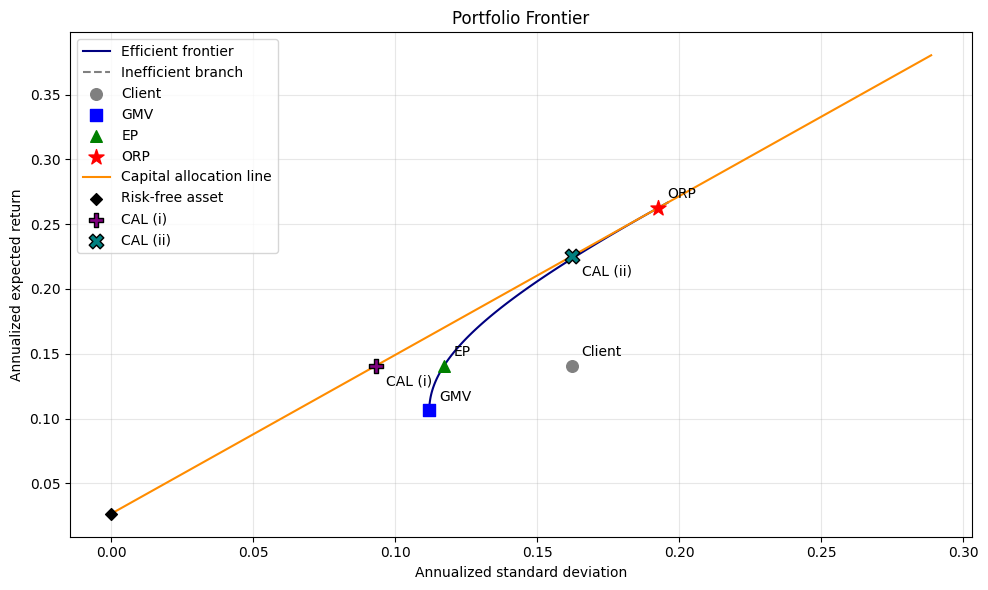

In [ ]:
"""
- Global minimum variance portfolio
- Efficient portfolio
- Optimal risky portfolio
- Efficient Fronter
- Capital Allocation Line & Fund Separation Theorem
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE = "sector_etf_returns__96_mos_.xlsx"
returns = pd.read_excel(
    FILE, sheet_name="Returns", index_col="Month End", parse_dates=True
)

etf_returns = returns.drop(columns=["Market", "Risk-Free"])

TICKERS = ["XLC", "XLY", "XLP", "XLE", "XLF", "XLV", "XLI", "XLK", "XLB", "XLRE", "XLU"]
COUNT = returns.shape[0]
ONE_VEC = np.ones((len(TICKERS), 1))  # Shape (11, 1)
n = len(TICKERS)

# Raise error for missing tickers:
missing = set(TICKERS) - set(etf_returns.columns)
assert not missing, f"Tickers not found in data: {missing}"

# Annualized mean-return vector:
mu = etf_returns.mean() * 12
MU = mu.reindex(TICKERS).to_numpy()

# Covariance Matrix:
cov_mat = etf_returns.cov() * 12
COV = cov_mat.loc[TICKERS, TICKERS].to_numpy()

# Annual Risk-Free Rate:
rf_rate = returns["Risk-Free"].mean() * 12


# User Input
def get_client_weights(tickers=TICKERS, seed=42, tol=1e-6):
    while True:
        raw = {}
        print("Enter a weight for each ticker as a decimal")
        print(
            "(Press Enter at the first prompt for a random portfolio; "
            "after that, blank = 0.)"
        )

        random_portfolio = False
        for i, ticker in enumerate(tickers):
            while True:
                entry = input(f"  {ticker:<5}: ").strip().rstrip("%")
                if entry == "":
                    if i == 0:
                        random_portfolio = True
                    else:
                        raw[ticker] = 0.0
                    break
                try:
                    value = float(entry)
                except ValueError:
                    print("    Please enter a number.")
                    continue
                if value < 0:
                    print("    Weights can't be negative.")
                    continue
                raw[ticker] = value
                break
            if random_portfolio:
                break

        if random_portfolio:
            rng = np.random.default_rng(seed)
            draw = rng.dirichlet(np.ones(len(tickers)))
            weights = dict(zip(tickers, draw))
            print(f"\nRandom long-only portfolio (Dirichlet, seed={seed}):")
        else:
            total = sum(raw.values())
            if total == 0:
                print("\nAll weights are zero. Let's try again.\n")
                continue
            if abs(total - 1) > tol:
                print(f"\nWeights summed to {total:.4f}; normalizing to 1.")
            weights = {t: w / total for t, w in raw.items()}
            print("\nWeights:")

        for ticker, w in weights.items():
            print(f"  {ticker:<5} {w:7.2%}")
        print(f"  {'Total':<5} {sum(weights.values()):7.2%}")

        confirm = input("\nUse these weights? [Y/n]: ").strip().lower()
        if confirm in ("", "y", "yes"):
            return weights
        print()


def check_budget_constraint(portfolio, tol=1e-6):
    W = (
        pd.Series(portfolio, dtype=float)
        .reindex(TICKERS)
        .fillna(0.0)
        .to_numpy()
        .reshape(-1, 1)
    )  # (n, 1)

    budget = (W.T @ ONE_VEC).item()  # Wᵀ1
    satisfied = np.isclose(budget, 1.0, atol=tol, rtol=0)

    print(f"Sum of weights: {budget:.7f}  ->  {'OK' if satisfied else 'VIOLATED'}")
    return satisfied


def get_portfolio_metrics(portfolio):
    # Align to TICKERS, then convert to column vectors / matrix
    W = (
        pd.Series(portfolio, dtype=float)
        .reindex(TICKERS)
        .fillna(0.0)
        .to_numpy()
        .reshape(-1, 1)
    )  # (n, 1)
    MU = mu.reindex(TICKERS).to_numpy().reshape(-1, 1)  # (n, 1)
    COV = cov_mat.loc[TICKERS, TICKERS].to_numpy()  # (n, n)

    exp_ret = (W.T @ MU).item()  # E[R_p] = WᵀMU
    variance = (W.T @ COV @ W).item()  # σ²_p  = WᵀΣW
    std = np.sqrt(variance)
    sharpe = (exp_ret - rf_rate) / std

    print(f"\nExpected return:    {exp_ret:.7f}")
    print(f"Variance:{variance:.7f}")
    print(f"Standard deviation: {std:.7f}")
    print(f"Sharpe ratio:       {sharpe:.7f}  (rf = {rf_rate:.7f})")

    return {
        "expected_return": exp_ret,
        "variance": variance,
        "std_dev": std,
        "sharpe_ratio": sharpe,
    }


def get_gmv():
    # Closed-form solution:
    cov_inv = np.linalg.inv(COV)
    W_closed = ((cov_inv @ ONE_VEC) / (ONE_VEC.T @ cov_inv @ ONE_VEC).item()).ravel()

    # Matrix solution:
    A = np.block([[2 * COV, ONE_VEC], [ONE_VEC.T, np.zeros((1, 1))]])

    # construct the b vector for the form Ax=b
    b = np.zeros(n + 1)  # num portfolio weights + 1 for the lagrange
    b[-1] = 1.0

    # solve for x = A^(-1)b
    x = np.linalg.inv(A) @ b
    W_matrix = x[:n]

    compare_methods = pd.DataFrame(
        {"Closed Form": W_closed, "Matrix Form": W_matrix}, index=TICKERS
    )
    print("\nGMV portfolio weights:")
    print(compare_methods.to_string(float_format=lambda w: f"{w:.6f}"))

    return {
        "closed_form": dict(zip(TICKERS, W_closed)),
        "matrix_solution": dict(zip(TICKERS, W_matrix)),
        "A": A,
        "b": b,
        "x": x,
    }


def get_efficient_portfolio(target):
    A = np.block(
        [
            [2 * COV, ONE_VEC.reshape(-1, 1), MU.reshape(-1, 1)],
            [ONE_VEC.T, np.zeros((1, 2))],
            [MU.reshape(1, -1), np.zeros((1, 2))],
        ]
    )

    # constructing b vector
    b = np.zeros(n + 2)
    b[-2] = 1.0
    b[-1] = target

    # solving for x
    x = np.linalg.solve(A, b)
    W = x[:n]

    return dict(zip(TICKERS, W))


def get_orp(rf=rf_rate):
    # mu - rf1
    excess_returns = MU.reshape(-1, 1) - rf * ONE_VEC

    cov_inv = np.linalg.inv(COV)
    numerator = cov_inv @ excess_returns
    denom = (ONE_VEC.T @ numerator).item()

    # zero division check:
    if np.isclose(denom, 0.0, atol=1e-12, rtol=0):
        raise ValueError("Cannot normalize tangency weights: denominator is near zero.")

    W = (numerator / denom).ravel()
    return dict(zip(TICKERS, W))


def check_orp():
    orp_weights = get_orp(rf_rate)
    print("\nOptimal risky portfolio weights:")
    for ticker, weight in orp_weights.items():
        print(f"  {ticker:<5} {weight:.6f}")

    budget_ok = check_budget_constraint(orp_weights)
    orp_metrics = get_portfolio_metrics(orp_weights)
    exceeds_rf = orp_metrics["expected_return"] > rf_rate

    print(f"\nRisk-free rate: {rf_rate:.7f}")
    print(f"Expected return exceeds risk-free rate: {exceeds_rf}")

    if not exceeds_rf:
        print(
            "The calculated portfolio does not satisfy the "
            "positive-excess-return tangency condition."
        )
    return {
        "weights": orp_weights,
        "metrics": orp_metrics,
        "budget_ok": budget_ok,
        "exceeds_rf": exceeds_rf,
    }


def efficient_frontier():
    # gmv = get_gmv()
    W_gmv = np.array([gmv["closed_form"][t] for t in TICKERS])

    target = client_metrics["expected_return"]
    ep_weights = get_efficient_portfolio(target)
    W_ep = np.array([ep_weights[t] for t in TICKERS])

    orp_weights = get_orp(rf_rate)
    W_orp = np.array([orp_weights[t] for t in TICKERS])

    mean_returns = MU.ravel()
    ret_gmv = (W_gmv @ mean_returns).item()
    ret_ep = (W_ep @ mean_returns).item()
    ret_orp = (W_orp @ mean_returns).item()

    # If EP equals GMV, they cannot generate the whole frontier
    if np.isclose(ret_gmv, ret_ep, atol=1e-12, rtol=0):
        raise ValueError(
            "The client's target return equals the GMV return. "
            "Choose a different target to generate the frontier."
        )

    a_orp = (ret_orp - ret_ep) / (ret_gmv - ret_ep)

    # Range includes a=0, a=1, and a_orp, with a margin
    step = 0.05
    lower = min(0.0, a_orp) - 0.10
    upper = max(1.0, a_orp) + 0.10

    start = int(np.floor(lower / step))
    stop = int(np.ceil(upper / step))
    a_values = np.arange(start, stop + 1) * step

    # Include the exact special values in addition to the grid
    a_values = np.unique(np.concatenate([a_values, [0.0, 1.0, a_orp]]))

    rows = []

    for a in a_values:
        W = a * W_gmv + (1 - a) * W_ep
        expected_return = (W @ mean_returns).item()
        variance = (W @ COV @ W).item()
        std_dev = np.sqrt(variance)

        rows.append(
            {
                "a": a,
                "expected_return": expected_return,
                "std_dev": std_dev,
            }
        )
    frontier = pd.DataFrame(rows)

    # Verify ORP combination
    W_reproduced = a_orp * W_gmv + (1 - a_orp) * W_ep
    weights_match = np.allclose(W_reproduced, W_orp, atol=1e-10, rtol=0)

    print("\nFrontier sweep:")
    print(frontier.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

    print(f"\na that reproduces the ORP: {a_orp:.10f}")
    print(f"ORP weights match: {weights_match}")
    print(
        "Maximum absolute weight difference:",
        f"{np.max(np.abs(W_reproduced - W_orp)):.3e}",
    )

    return {
        "frontier": frontier,
        "a_orp": a_orp,
        "orp_weights_match": weights_match,
        "reproduced_orp_weights": dict(zip(TICKERS, W_reproduced)),
    }


"""Chat Prompt: Given this function [...] give the python code that implements
    def plot_frontier() that creates a plot for the efficient frontier calculated.

    Now, update the function to include the CAL on the same plot
"""


def plot_portfolios():
    frontier = frontier_results["frontier"]
    gmv_return = closed_metrics["expected_return"]

    # Separate the efficient and inefficient branches
    upper = frontier[frontier["expected_return"] >= gmv_return - 1e-12].sort_values(
        "expected_return"
    )

    lower = frontier[frontier["expected_return"] < gmv_return].sort_values(
        "expected_return"
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(
        upper["std_dev"],
        upper["expected_return"],
        color="navy",
        label="Efficient frontier",
    )

    ax.plot(
        lower["std_dev"],
        lower["expected_return"],
        color="gray",
        linestyle="--",
        label="Inefficient branch",
    )

    # Mark the portfolios calculated in earlier steps
    portfolios = [
        ("Client", client_metrics, "gray", "o"),
        ("GMV", closed_metrics, "blue", "s"),
        ("EP", efficient_metrics, "green", "^"),
        ("ORP", orp["metrics"], "red", "*"),
    ]

    for label, metrics, color, marker in portfolios:
        risk = metrics["std_dev"]
        expected_return = metrics["expected_return"]

        ax.scatter(
            risk,
            expected_return,
            color=color,
            marker=marker,
            s=130 if label == "ORP" else 70,
            label=label,
            zorder=5,
        )

        ax.annotate(
            label,
            (risk, expected_return),
            xytext=(7, 7),
            textcoords="offset points",
        )

    ax.set(
        title="Portfolio Frontier",
        xlabel="Annualized standard deviation",
        ylabel="Annualized expected return",
    )

    ax.grid(alpha=0.3)

    ax.plot(
        cal_results["std_dev"],
        cal_results["expected_return"],
        color="darkorange",
        label="Capital allocation line",
    )

    ax.scatter(
        0,
        rf_rate,
        color="black",
        marker="D",
        label="Risk-free asset",
        zorder=5,
    )

    # Step 8 CAL portfolios, marked and labeled on the CAL
    cal_points = [
        ("CAL (i)", "Same expected return", "purple", "P"),
        ("CAL (ii)", "Same standard deviation", "teal", "X"),
    ]
    for label, key, color, marker in cal_points:
        point = cal_comparisons[key]
        ax.scatter(
            point["std_dev"],
            point["expected_return"],
            color=color,
            marker=marker,
            s=110,
            edgecolor="black",
            label=label,
            zorder=6,
        )
        ax.annotate(
            label,
            (point["std_dev"], point["expected_return"]),
            xytext=(7, -14),
            textcoords="offset points",
        )

    ax.legend()
    fig.tight_layout()
    plt.show()

    return fig, ax


def capital_allocation_line():
    orp_return = orp["metrics"]["expected_return"]
    orp_std = orp["metrics"]["std_dev"]

    y_values = np.arange(31) * 0.05

    rows = []
    for y in y_values:
        expected_return = rf_rate + y * (orp_return - rf_rate)

        std_dev = abs(y) * orp_std

        rows.append(
            {
                "y": y,
                "risk_free_weight": 1 - y,
                "expected_return": expected_return,
                "std_dev": std_dev,
            }
        )
    cal = pd.DataFrame(rows)
    print("\nCapital allocation line:")
    print(cal.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

    return cal


def compare_cal_portfolios():
    client_return = client_metrics["expected_return"]
    client_std = client_metrics["std_dev"]

    orp_return = orp["metrics"]["expected_return"]
    orp_std = orp["metrics"]["std_dev"]
    orp_weights = orp["weights"]

    excess_return = orp_return - rf_rate

    if excess_return <= 0 or orp_std <= 0:
        raise ValueError(
            "The ORP must have positive excess return "
            "and positive standard deviation."
        )

    # Two choices of exposure to the ORP
    allocations = {
        "Same expected return": ((client_return - rf_rate) / excess_return),
        "Same standard deviation": client_std / orp_std,
    }
    results = {}

    for name, y in allocations.items():
        # Total-portfolio allocations
        rf_weight = 1 - y
        etf_weights = {ticker: y * orp_weights[ticker] for ticker in TICKERS}

        # Metrics including the risk-free asset
        expected_return = rf_rate + y * excess_return
        std_dev = abs(y) * orp_std

        sharpe = (expected_return - rf_rate) / std_dev if std_dev > 0 else np.nan

        budget = rf_weight + sum(etf_weights.values())

        print(f"\n{name}:")
        print(f"y (weight in ORP): {y:.7f}")
        print(f"Weight in risk-free asset: {rf_weight:.7f}")

        print("\nETF weights:")
        for ticker, weight in etf_weights.items():
            print(f"  {ticker:<5} {weight:.7f}")

        print(f"\nTotal weight including risk-free: {budget:.7f}")
        print(f"Expected return:    {expected_return:.7f}")
        print(f"Standard deviation: {std_dev:.7f}")
        print(f"Sharpe ratio:       {sharpe:.7f}")

        if y > 1:
            print(f"Borrows {y - 1:.2%} of initial capital " f"at rf = {rf_rate:.7f}.")

        if name == "Same expected return":
            improvement = client_std - std_dev

            print(
                f"\nAt the same expected return "
                f"({client_return:.2%}), standard deviation "
                f"changes from {client_std:.2%} to {std_dev:.2%}."
            )
            print(f"Risk reduction: {improvement * 100:.4f} " "percentage points.")

        else:
            improvement = expected_return - client_return

            print(
                f"\nAt the same standard deviation "
                f"({client_std:.2%}), expected return "
                f"changes from {client_return:.2%} "
                f"to {expected_return:.2%}."
            )
            print(f"Return increase: {improvement * 100:.4f} " "percentage points.")

        results[name] = {
            "y": y,
            "risk_free_weight": rf_weight,
            "etf_weights": etf_weights,
            "expected_return": expected_return,
            "std_dev": std_dev,
            "sharpe_ratio": sharpe,
            "improvement": improvement,
        }

    return results


if __name__ == "__main__":
    """
    For testing: equal weighted portfolios 0.0909
    """
    # Step 2: Client's portfolio
    client_weights = get_client_weights()
    check_budget_constraint(client_weights)
    print("Client Portfolio:")
    client_metrics = get_portfolio_metrics(client_weights)

    # Step 3: GMV portfolio
    gmv = get_gmv()

    # Closed-form weights
    print("\nClosed-form GMV:")
    check_budget_constraint(gmv["closed_form"])
    closed_metrics = get_portfolio_metrics(gmv["closed_form"])

    # Matrix-solution weights
    print("\nMatrix-solution GMV:")
    check_budget_constraint(gmv["matrix_solution"])
    matrix_metrics = get_portfolio_metrics(gmv["matrix_solution"])

    # Step 4: Efficient Portfolio
    target = client_metrics["expected_return"]
    efficient_weights = get_efficient_portfolio(target)

    print("\nPortfolio at the client's expected return:")
    for ticker, weight in efficient_weights.items():
        print(f"  {ticker:<5} {weight:.6f}")

    check_budget_constraint(efficient_weights)
    efficient_metrics = get_portfolio_metrics(efficient_weights)

    print(
        "\nTarget return achieved:",
        np.isclose(efficient_metrics["expected_return"], target, atol=1e-10, rtol=1e-8),
    )

    # Step 5: Optimal Risky Portfolio
    orp = check_orp()

    # Step 6: Efficient Frontier
    frontier_results = efficient_frontier()

    # Step 7: Capital Allocation Line
    cal_results = capital_allocation_line()

    # Step 8: CAL by Fund Separation
    cal_comparisons = compare_cal_portfolios()

    # Step 9: Plot the portfolios with the frontier and CAL
    fig, ax = plot_portfolios()

## Part 2: Rolling Out-of-Sample Test
**Question:** if we only use *past* data to build a portfolio, does it beat the client in months it has never seen?

**Plan:** 12 times, use 60 months to pick weights, then score those weights on the next 3 months.
Stitch the 12 three-month pieces together to get 36 out-of-sample months (Sep 2023 to Aug 2026).

## Step 1: Settings and data

In [ ]:
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

R = returns[TICKERS]          
MKT = returns["Market"]       
RF = returns["Risk-Free"]     

WINDOW = 60                  
HOLD = 3                      
TRIALS = 12                   
LAM = 0.5                    
CAP = 0.20                    

MEANS = ["Raw", "CAPM"]
COVS = ["Sample", "LW"]
RULES = ["Unconstrained", "Long-only", "Cap 20%"]
NAMES = [f"{m} | {c} | {r}" for m in MEANS for c in COVS for r in RULES]
print(len(NAMES), "portfolios:", *NAMES, sep="\n  ")

12
  portfolios:
  Raw | Sample | Unconstrained
  Raw | Sample | Long-only
  Raw | Sample | Cap 20%
  Raw | LW | Unconstrained
  Raw | LW | Long-only
  Raw | LW | Cap 20%
  CAPM | Sample | Unconstrained
  CAPM | Sample | Long-only
  CAPM | Sample | Cap 20%
  CAPM | LW | Unconstrained
  CAPM | LW | Long-only
  CAPM | LW | Cap 20%


## Step 2: Estimate inputs from ONE 60-month window
Everything here uses only the 60 months passed in, so there is no look-ahead.

In [ ]:
def estimate(R_win, mkt_win, rf_win):
    rf_m = rf_win.mean()

    mu_raw = R_win.mean() * 12

    # Means, version 2: shrink toward CAPM
    #   beta_i = Cov(ETF excess, market excess) / Var(market excess)
    #   CAPM mean = rf + beta * (average market excess return)
    #   final = 50% historical + 50% CAPM
    etf_ex = R_win.sub(rf_win, axis=0)
    mkt_ex = mkt_win - rf_win
    beta = etf_ex.apply(lambda col: col.cov(mkt_ex)) / mkt_ex.var()
    mu_capm = (1 - LAM) * R_win.mean() + LAM * (rf_m + beta * mkt_ex.mean())
    mu_capm = mu_capm * 12

    # Covariance, version 1: normal sample covariance
    cov_sample = R_win.cov() * 12
    # Covariance, version 2: Ledoit-Wolf (shrinks the noisy sample covariance toward a simple target)
    cov_lw = LedoitWolf().fit(R_win).covariance_ * 12

    return {
        "mu": {"Raw": mu_raw.to_numpy(), "CAPM": mu_capm.to_numpy()},
        "cov": {"Sample": cov_sample.to_numpy(), "LW": cov_lw},
        "rf": rf_m * 12,
    }

## Step 3: Find the max-Sharpe weights
* **Unconstrained:** same ORP formula as Part 1.
* **Long-only / Cap 20%:** no formula exists, so the computer searches for the best weights (SLSQP).

In [ ]:
def sharpe(w, mu, cov, rf):
    return (w @ mu - rf) / np.sqrt(w @ cov @ w)


def best_weights(mu, cov, rf, rule):
    n_assets = len(mu)

    if rule == "Unconstrained":                       # Part 1 ORP formula
        z = np.linalg.inv(cov) @ (mu - rf)
        return z / z.sum()

    max_w = 1.0 if rule == "Long-only" else CAP
    result = minimize(
        lambda w: -sharpe(w, mu, cov, rf),
        x0=np.ones(n_assets) / n_assets,
        method="SLSQP",
        bounds=[(0, max_w)] * n_assets,
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    return result.x

## Step 4: The rolling loop
Trial 1 estimates on months 1–60 and scores 61–63. Trial 2 estimates on 4–63 and scores 64–66. … Trial 12 scores 94–96.

In [ ]:
weights = {name: [] for name in NAMES}
oos = {name: [] for name in NAMES}
in_sample = {name: [] for name in NAMES}
cond_rows = []
solver_ok = []
rng = np.random.default_rng(42)

for k in range(TRIALS):
    start = 3 * k
    end = start + WINDOW

    est = estimate(R.iloc[start:end], MKT.iloc[start:end], RF.iloc[start:end])

    R_next = R.iloc[end:end + HOLD].to_numpy()

    cond_rows.append({
        "Window": f"{R.index[start]:%b %Y} – {R.index[end - 1]:%b %Y}",
        "Scored": f"{R.index[end]:%b %Y} – {R.index[end + HOLD - 1]:%b %Y}",
        "κ Sample": np.linalg.cond(est["cov"]["Sample"]),
        "κ LW": np.linalg.cond(est["cov"]["LW"]),
    })

    # Build all 12 portfolios, hold each for 3 months, and save the returns
    for m in MEANS:
        for c in COVS:
            for r in RULES:
                name = f"{m} | {c} | {r}"
                mu, cov, rf = est["mu"][m], est["cov"][c], est["rf"]
                w = best_weights(mu, cov, rf, r)
                weights[name].append(w)
                in_sample[name].append(sharpe(w, mu, cov, rf))
                oos[name].extend(R_next @ w)

                # Solver check: no random valid portfolio should beat the optimizer
                if r != "Unconstrained":
                    W_rand = rng.dirichlet(np.ones(len(TICKERS)), 20000)
                    if r == "Cap 20%":
                        W_rand = W_rand[W_rand.max(axis=1) <= CAP]
                    sr_rand = (W_rand @ mu - rf) / np.sqrt(np.einsum("ij,jk,ik->i", W_rand, cov, W_rand))
                    solver_ok.append(sharpe(w, mu, cov, rf) >= sr_rand.max())

print(f"Solver check: optimizer beat every random portfolio in {sum(solver_ok)} of {len(solver_ok)} cases")
print("Each portfolio now has", len(oos[NAMES[0]]), "out-of-sample months")

Solver check: optimizer beat every random portfolio in 96 of 96 cases
Each portfolio now has 36 out-of-sample months


## Step 5: Table 2 — score everything on the 36 unseen months

In [ ]:
R_36 = R.iloc[WINDOW:].to_numpy()
rf_36 = RF.iloc[WINDOW:].mean() * 12
w_client = np.array([client_weights[t] for t in TICKERS])
client_36 = R_36 @ w_client


def score(r):
    r = np.array(r)
    er = r.mean() * 12
    sd = r.std(ddof=1) * np.sqrt(12)
    return er, sd, (er - rf_36) / sd, np.prod(1 + r) - 1


table2 = {}
for name in NAMES:
    W = np.array(weights[name])
    er, sd, sr, cum = score(oos[name])
    table2[name] = {
        "Return": er, "Std dev": sd, "Sharpe": sr, "Cumulative": cum,
        "Gross exposure": np.abs(W).sum(axis=1).mean(),
        "Largest weight": W.max(),
        "Turnover/qtr": (0.5 * np.abs(np.diff(W, axis=0)).sum(axis=1)).mean(),
    }
er, sd, sr, cum = score(client_36)
table2["Given client"] = {"Return": er, "Std dev": sd, "Sharpe": sr, "Cumulative": cum,
                          "Gross exposure": np.abs(w_client).sum(), "Largest weight": w_client.max(),
                          "Turnover/qtr": 0.0}
table2 = pd.DataFrame(table2).T
print(f"Table 2: Out-of-sample results (36 months, annualized, rf = {rf_36:.4%})")
print(table2.round(4).to_string())

Table 2: Out-of-sample results (36 months, annualized, rf = 4.4833%)
                               Return  Std dev  Sharpe  Cumulative  Gross exposure  Largest weight  Turnover/qtr
Raw | Sample | Unconstrained   0.0489   0.4009  0.0102     -0.0853         10.6326          8.5931        3.0626
Raw | Sample | Long-only       0.2272   0.1434  1.2716      0.9084          1.0000          1.0000        0.1756
Raw | Sample | Cap 20%         0.1454   0.0975  1.0316      0.5220          1.0000          0.2000        0.1750
Raw | LW | Unconstrained       0.1395   0.2188  0.4325      0.4159          5.0065          3.4388        1.2608
Raw | LW | Long-only           0.2201   0.1382  1.2682      0.8727          1.0000          0.9947        0.1907
Raw | LW | Cap 20%             0.1454   0.0977  1.0299      0.5219          1.0000          0.2000        0.1710
CAPM | Sample | Unconstrained  0.1311   0.2246  0.3839      0.3766          5.5715          3.5855        1.2854
CAPM | Sample | Long-only  

## Step 5b: In-sample vs out-of-sample Sharpe
In-sample = Sharpe on the 60 months used to build the weights (averaged over the 12 windows). Out-of-sample = Sharpe on the 36 unseen months.

In [ ]:
compare = pd.DataFrame({
    "In-sample Sharpe (avg of 12 windows)": {n: np.mean(in_sample[n]) for n in NAMES},
    "Out-of-sample Sharpe (36 months)": table2.loc[NAMES, "Sharpe"],
})
compare["Change"] = compare.iloc[:, 1] - compare.iloc[:, 0]
print("In-sample vs out-of-sample Sharpe ratios")
print(compare.round(2).to_string())

In-sample vs out-of-sample Sharpe ratios
                               In-sample Sharpe (avg of 12 windows)  Out-of-sample Sharpe (36 months)  Change
Raw | Sample | Unconstrained                                   1.47                              0.01   -1.46
Raw | Sample | Long-only                                       1.01                              1.27    0.27
Raw | Sample | Cap 20%                                         0.85                              1.03    0.18
Raw | LW | Unconstrained                                       1.30                              0.43   -0.87
Raw | LW | Long-only                                           1.03                              1.27    0.24
Raw | LW | Cap 20%                                             0.88                              1.03    0.15
CAPM | Sample | Unconstrained                                  0.96                              0.38   -0.58
CAPM | Sample | Long-only                                      0.82            

## Step 6: Table 3 — compare with 10,000 random clients

In [ ]:
sim_w = np.random.default_rng(42).dirichlet(np.ones(len(TICKERS)), size=10000)   # 10,000 random portfolios
sim_r = R_36 @ sim_w.T                                                            # their 36 monthly returns
sim_er = sim_r.mean(axis=0) * 12
sim_sd = sim_r.std(axis=0, ddof=1) * np.sqrt(12)
sim_sr = (sim_er - rf_36) / sim_sd

table3a = pd.DataFrame(
    {f"{p}th": [np.percentile(x, p) for x in (sim_er, sim_sd, sim_sr)] for p in [5, 25, 50, 75, 95]},
    index=["Return", "Std dev", "Sharpe"],
)
table3b = pd.DataFrame({
    "Sharpe": table2["Sharpe"],
    "Beats % of random clients": [(sim_sr < s).mean() for s in table2["Sharpe"]],
})
print("Table 3a: Random clients (percentiles)")
print(table3a.round(4).to_string())
print("\nTable 3b: Share of random clients beaten on Sharpe")
print(table3b.to_string(formatters={"Sharpe": "{:.4f}".format, "Beats % of random clients": "{:.1%}".format}))

Table 3a: Random clients (percentiles)
            5th    25th    50th    75th    95th
Return   0.1320  0.1447  0.1549  0.1658  0.1835
Std dev  0.1038  0.1095  0.1142  0.1197  0.1288
Sharpe   0.7395  0.8680  0.9684  1.0659  1.2032

Table 3b: Share of random clients beaten on Sharpe
                              Sharpe Beats % of random clients
Raw | Sample | Unconstrained  0.0102                      0.0%
Raw | Sample | Long-only      1.2716                     98.5%
Raw | Sample | Cap 20%        1.0316                     66.8%
Raw | LW | Unconstrained      0.4325                      0.0%
Raw | LW | Long-only          1.2682                     98.4%
Raw | LW | Cap 20%            1.0299                     66.4%
CAPM | Sample | Unconstrained 0.3839                      0.0%
CAPM | Sample | Long-only     1.2132                     95.7%
CAPM | Sample | Cap 20%       1.0723                     76.3%
CAPM | LW | Unconstrained     0.7870                     10.2%
CAPM | LW | Long-only   

## Step 7: Table 4 — condition numbers (how sensitive the weights are to estimation errors)

In [ ]:
table4 = pd.DataFrame(cond_rows, index=range(1, TRIALS + 1))
table4["Ratio"] = table4["κ Sample"] / table4["κ LW"]
print("Table 4: Condition numbers by window")
print(table4.round(2).to_string())

Table 4: Condition numbers by window
                 Window               Scored  κ Sample   κ LW  Ratio
1   Sep 2018 – Aug 2023  Sep 2023 – Nov 2023    143.97  59.21   2.43
2   Dec 2018 – Nov 2023  Dec 2023 – Feb 2024    159.79  62.55   2.55
3   Mar 2019 – Feb 2024  Mar 2024 – May 2024    160.27  56.71   2.83
4   Jun 2019 – May 2024  Jun 2024 – Aug 2024    175.71  57.30   3.07
5   Sep 2019 – Aug 2024  Sep 2024 – Nov 2024    176.60  54.92   3.22
6   Dec 2019 – Nov 2024  Dec 2024 – Feb 2025    180.41  56.52   3.19
7   Mar 2020 – Feb 2025  Mar 2025 – May 2025    181.34  53.70   3.38
8   Jun 2020 – May 2025  Jun 2025 – Aug 2025    146.25  55.21   2.65
9   Sep 2020 – Aug 2025  Sep 2025 – Nov 2025    145.32  54.38   2.67
10  Dec 2020 – Nov 2025  Dec 2025 – Feb 2026    121.85  48.61   2.51
11  Mar 2021 – Feb 2026  Mar 2026 – May 2026    132.37  50.29   2.63
12  Jun 2021 – May 2026  Jun 2026 – Aug 2026    126.56  48.52   2.61


## Step 8: Charts

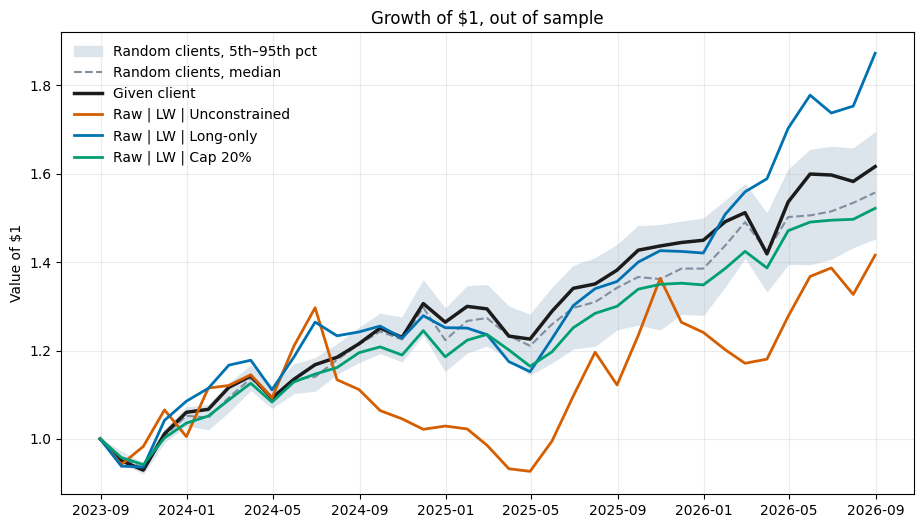

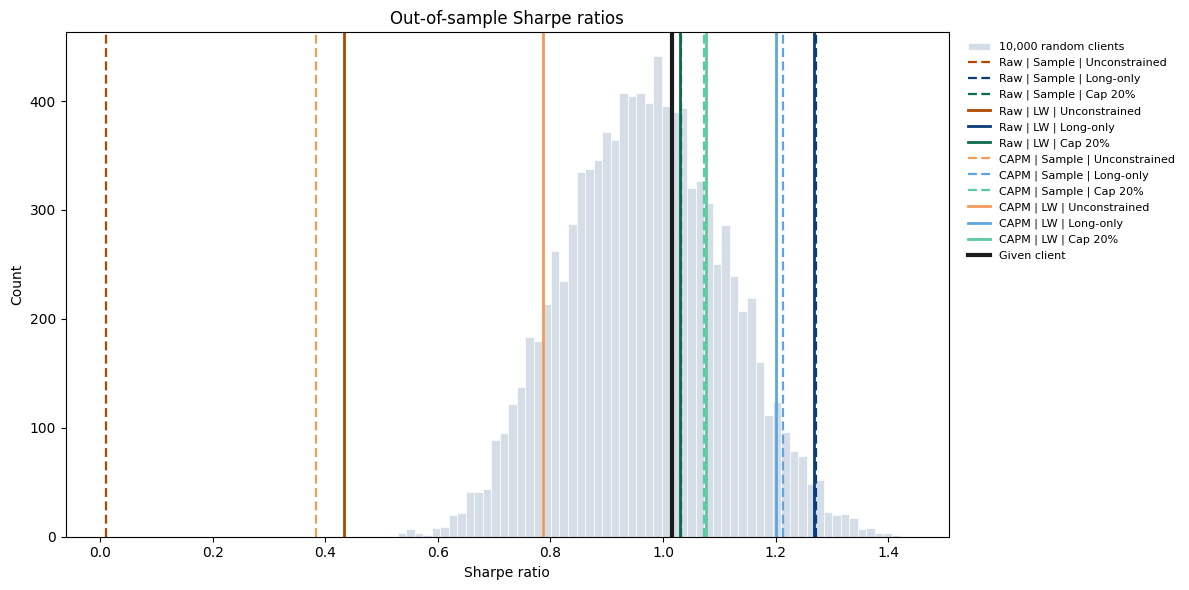

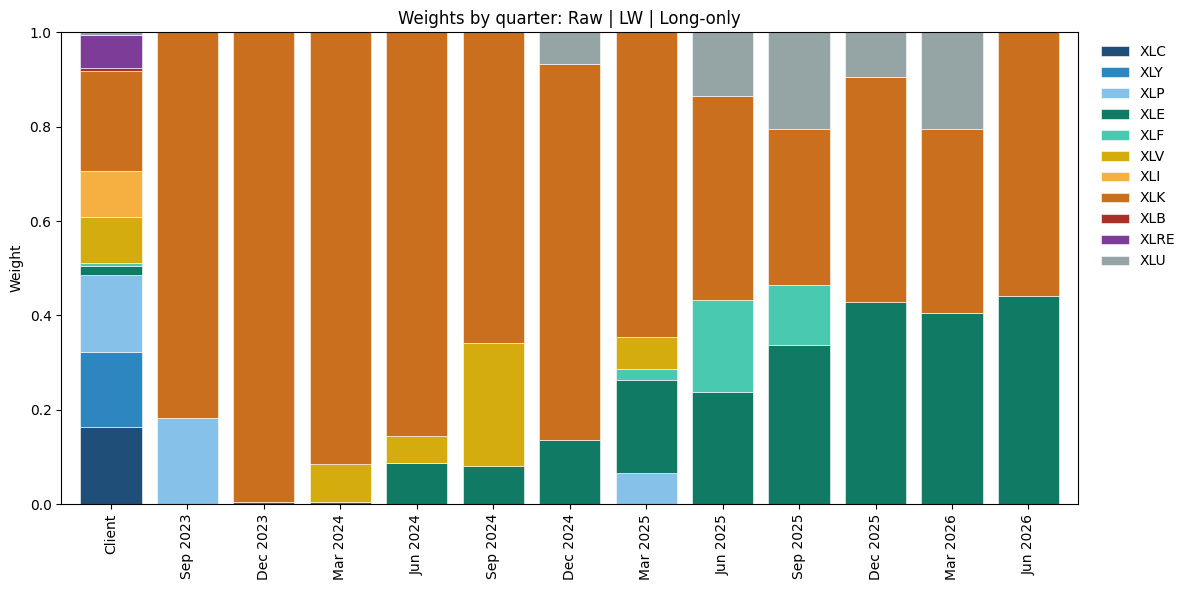

In [ ]:
RULE_COLORS = {"Unconstrained": "#D55E00",
               "Long-only":     "#0072B2",
               "Cap 20%":       "#009E73"}
CLIENT_COLOR = "#1B1B1B"
BAND_COLOR   = "#DCE4EC"
MEDIAN_COLOR = "#7F8FA0"
HIST_COLOR   = "#B9CCE0"
TICKER_COLORS = ["#1F4E79", "#2E86C1", "#85C1E9", "#117A65", "#48C9B0", "#D4AC0D",
                 "#F5B041", "#CA6F1E", "#A93226", "#7D3C98", "#95A5A6"]

dates = [R.index[WINDOW - 1]] + list(R.index[WINDOW:])

def grow(r):
    return np.concatenate([[1], np.cumprod(1 + np.array(r))])

# Chart 1: growth of $1
sim_grow = np.vstack([np.ones(10000), np.cumprod(1 + sim_r, axis=0)])
plt.figure(figsize=(11, 6))
plt.fill_between(dates, np.percentile(sim_grow, 5, axis=1), np.percentile(sim_grow, 95, axis=1),
                 color=BAND_COLOR, label="Random clients, 5th–95th pct")
plt.plot(dates, np.median(sim_grow, axis=1), color=MEDIAN_COLOR, lw=1.5, ls="--",
         label="Random clients, median")
plt.plot(dates, grow(client_36), color=CLIENT_COLOR, lw=2.5, label="Given client")
for r in RULES:
    plt.plot(dates, grow(oos[f"Raw | LW | {r}"]), color=RULE_COLORS[r], lw=2, label=f"Raw | LW | {r}")
plt.title("Growth of $1, out of sample")
plt.ylabel("Value of $1"); plt.legend(frameon=False); plt.grid(alpha=0.25); plt.show()

# Chart 2: histogram of random clients' Sharpe ratios
# color family = rule, shade = expected-return input (Raw dark, CAPM light),
# line style = covariance estimator (LW solid, Sample dashed)
LINE_COLORS = {
    ("Raw",  "Unconstrained"): "#B34700",   # dark orange
    ("CAPM", "Unconstrained"): "#F39C5A",   # light orange
    ("Raw",  "Long-only"):     "#0B3C7A",   # navy
    ("CAPM", "Long-only"):     "#5DA5E0",   # sky blue
    ("Raw",  "Cap 20%"):       "#0B6B4F",   # forest green
    ("CAPM", "Cap 20%"):       "#5CC9A0",   # mint
}

plt.figure(figsize=(12, 6))
plt.hist(sim_sr, bins=60, color="#D5DDE6", edgecolor="white", linewidth=0.5,
         label="10,000 random clients")
for name in NAMES:
    inp, est, rule = name.split(" | ")
    plt.axvline(table2.loc[name, "Sharpe"], label=name,
                color=LINE_COLORS[(inp, rule)],
                lw=2 if est == "LW" else 1.6,
                linestyle="-" if est == "LW" else (0, (4, 2)))
plt.axvline(table2.loc["Given client", "Sharpe"], color="#1B1B1B", lw=3, label="Given client")
plt.title("Out-of-sample Sharpe ratios"); plt.xlabel("Sharpe ratio"); plt.ylabel("Count")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# Chart 3: stacked weights by quarter (client first)
pick = "Raw | LW | Long-only"
bars = pd.DataFrame([w_client] + weights[pick], columns=TICKERS,
                    index=["Client"] + [f"{R.index[WINDOW + 3 * k]:%b %Y}" for k in range(TRIALS)])
bars.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.8,
          color=TICKER_COLORS[:len(TICKERS)], edgecolor="white", linewidth=0.4)
plt.title(f"Weights by quarter: {pick}"); plt.ylabel("Weight")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()